# 93 · An action tokenizer from scratch: percentile bins, round-trip error in millimeters and milliradians

In [1]:
import os, numpy as np, matplotlib.pyplot as plt
from vlacourse import list_episodes, load_episode

DATA = os.path.abspath("../data/tabletop_panda_v1")
NAMES = ["dx", "dy", "dz", "droll", "dpitch", "dyaw", "grip"]

class UniformActionTokenizer:
    def __init__(self, data, n_bins=256, lo_pct=1, hi_pct=99, vocab_offset=0):
        flat = data.reshape(-1, data.shape[-1])
        self.lo, self.hi = np.percentile(flat, lo_pct, 0), np.percentile(flat, hi_pct, 0)
        self.hi = np.where(self.hi - self.lo < 1e-8, self.lo + 1e-8, self.hi)
        self.n_bins, self.offset = n_bins, vocab_offset

    def encode(self, x):
        z = np.clip((x - self.lo) / (self.hi - self.lo), 0, 1 - 1e-6)
        return (z * self.n_bins).astype(np.int64) + self.offset

    def decode(self, ids):
        z = (ids - self.offset + 0.5) / self.n_bins
        return z * (self.hi - self.lo) + self.lo

def physical_mae(tok, actions):
    mae = np.abs(tok.decode(tok.encode(actions)) - actions).mean(0)
    return mae[:3] * 1000, mae[3:6] * 1000, mae[6]

In [2]:
A = np.concatenate([load_episode(p)["action"] for p in list_episodes(DATA)])
print("actions:", A.shape)
tok = UniformActionTokenizer(A, 256)
ids = tok.encode(A[:3]); print("first 3 actions -> token ids:\n", ids)
print("decoded:\n", tok.decode(ids).round(4)); print("original:\n", A[:3].round(4))

actions: (8420, 7)
first 3 actions -> token ids:
 [[153 191  26   0   0 255   0]
 [153 191  26   0   0 255   0]
 [153 191  26   0   0 163   0]]
decoded:
 [[ 0.0036  0.0192 -0.0378  0.      0.      0.2988  0.002 ]
 [ 0.0036  0.0192 -0.0378  0.      0.      0.2988  0.002 ]
 [ 0.0036  0.0192 -0.0378  0.      0.      0.0832  0.002 ]]
original:
 [[ 0.0037  0.0193 -0.0379  0.      0.      0.3     0.    ]
 [ 0.0037  0.0193 -0.0379  0.      0.      0.3     0.    ]
 [ 0.0037  0.0193 -0.0379  0.      0.      0.0835  0.    ]]


In [3]:
t, r, g = physical_mae(tok, A)
print(f"256 bins: translation MAE {t.round(3)} mm | rotation MAE {r.round(3)} mrad | gripper MAE {g:.4f}")
print(f"bin width: translation {((tok.hi - tok.lo)[:3] / 256 * 1000).round(3)} mm, yaw {((tok.hi - tok.lo)[5] / 256 * 1000):.2f} mrad")
print("expected MAE ≈ bin width / 4 for values spread uniformly inside a bin")

256 bins: translation MAE [0.203 0.164 0.158] mm | rotation MAE [0.    0.    1.153] mrad | gripper MAE 0.0020
bin width: translation [0.217 0.316 0.372] mm, yaw 2.34 mrad
expected MAE ≈ bin width / 4 for values spread uniformly inside a bin


In [4]:
minmax = UniformActionTokenizer(A, 256, lo_pct=0, hi_pct=100)
A_out = A.copy(); A_out[123, 0] = 0.5
glitch = UniformActionTokenizer(A_out, 256, lo_pct=0, hi_pct=100)
robust = UniformActionTokenizer(A_out, 256, lo_pct=1, hi_pct=99)
for name, tk in [("min/max (clean data)", minmax), ("min/max + ONE glitch frame", glitch), ("1st/99th percentile + glitch", robust)]:
    print(f"{name:30s} dx bin width {(tk.hi - tk.lo)[0] / 256 * 1000:7.3f} mm  dx MAE {physical_mae(tk, A)[0][0]:.3f} mm")

min/max (clean data)           dx bin width   0.378 mm  dx MAE 0.138 mm
min/max + ONE glitch frame     dx bin width   2.147 mm  dx MAE 0.754 mm
1st/99th percentile + glitch   dx bin width   0.217 mm  dx MAE 0.203 mm


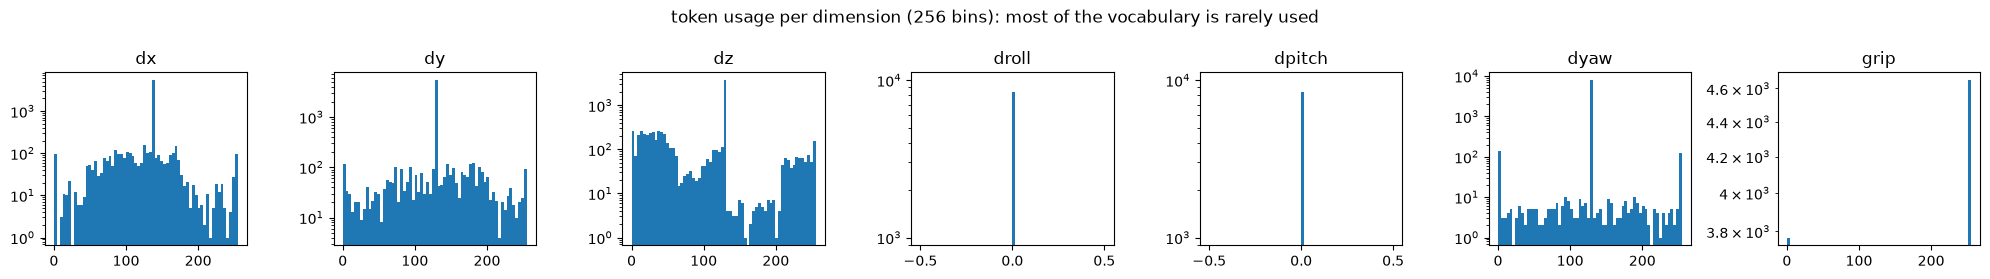

distinct tokens actually used per dimension: {'dx': 187, 'dy': 217, 'dz': 227, 'droll': 1, 'dpitch': 1, 'dyaw': 175, 'grip': 2}


In [5]:
fig, axes = plt.subplots(1, 7, figsize=(20, 2.8))
for i, ax in enumerate(axes):
    ax.hist(tok.encode(A)[:, i], bins=64); ax.set_title(NAMES[i]); ax.set_yscale("log")
plt.suptitle("token usage per dimension (256 bins): most of the vocabulary is rarely used"); plt.tight_layout(); plt.show()
used = [len(np.unique(tok.encode(A)[:, i])) for i in range(7)]
print("distinct tokens actually used per dimension:", dict(zip(NAMES, used)))